# 3.2 Caracterização das bases: potência dos sistemas e meteorologia

**Fonte brasileira:** `Leopoldo_base_consolidada_5min.csv`, localizado na raiz do projeto e gerado manualmente pelo pesquisador com `data.ipynb`. Este notebook apenas lê o CSV; não executa nem modifica `data.ipynb`, não refaz o merge e não altera o CSV fornecido.

A análise brasileira utiliza a potência `total_active_power_w`, convertida de W para kW, e os 55 canais físicos da estação presentes no CSV. Contadores de energia e potência DC permanecem fora do recorte descritivo deste notebook.

**Austrália:** `Active_Power` do sistema e os nove canais meteorológicos do arquivo original. O tratamento da fonte australiana permanece o mesmo.

Cada tabela identifica a variável e seu denominador de cobertura. As figuras de potência consideram somente a potência. A meteorologia é descritiva e não se torna entrada do cenário univariado. Nenhum alvo do experimento diário é alterado.

Execute de cima para baixo com as dependências do projeto; neste computador foi utilizado o ambiente `anomaly_detection`.


In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib
matplotlib.use("Agg")
from IPython.display import display, Image, Markdown

RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/energia_transfer").is_dir())
if str(RAIZ / "src") not in sys.path:
    sys.path.insert(0, str(RAIZ / "src"))
from energia_transfer.caracterizacao_sistemas_tcc import preparar_caracterizacao_sistemas, gerar_figuras_sistemas

pd.set_option("display.max_rows", 100)
pd.set_option("display.max_columns", 22)
pd.set_option("display.float_format", lambda v: f"{v:.3f}")
ARQUIVO_BRASIL = RAIZ / "Leopoldo_base_consolidada_5min.csv"
analise = preparar_caracterizacao_sistemas(RAIZ, arquivo_brasil=ARQUIVO_BRASIL)
indice = gerar_figuras_sistemas(analise)
fontes = analise["fontes"]
tabelas = analise["tabelas"]
PASTA = analise["pasta"]

def figura(numero, largura=1050):
    item = indice[numero - 1]
    display(Image(filename=str(analise["figuras"] / (item["arquivo"] + ".png")), width=largura))
    display(Markdown(f"**Figura 3.2-{numero:02d}: {item['titulo']}.** {item['legenda']}\n\nFonte: elaboração própria a partir das bases analisadas."))

print("Relatórios:", PASTA)
print("Figuras:", len(indice))


Lendo potência do sistema australiano e canais meteorológicos.
Lendo exclusivamente a base brasileira fornecida: Leopoldo_base_consolidada_5min.csv
Relatórios: C:\Users\camil\Documents\transfer-learning-energy-forecast-tcc\reports\tcc\caracterizacao_sistemas
Figuras: 7


## Convenções de cobertura e valores ausentes

Cada sistema é analisado em uma grade de cinco minutos, com 288 intervalos esperados por dia, incluindo zeros observados. O CSV brasileiro agora contém a grade completa de 2025. Os registros de inversores e estação foram associados independentemente no `data.ipynb`, preservando potência mesmo quando falta meteorologia.

**Cobertura temporal:** valores numéricos finitos divididos por todos os intervalos esperados. **Preenchimento nos intervalos com registro:** valores disponíveis divididos pelos horários com registro da respectiva fonte. Os indicadores `tem_registro_inversores` e `tem_registro_estacao` distinguem observações de linhas vazias da grade.

As classes são: sem registro da fonte, registro sem valor disponível e valor disponível. A falta de estação não torna a potência ausente. Valores negativos finitos são preservados e sinalizados para inspeção.

A soma dos inversores continua admitindo parcelas disponíveis (`min_count=1`). `n_inversores_potencia` identifica oito contribuintes ou soma parcial. A cobertura considera todas as potências finitas do CSV, sem excluir as somas parciais.


## 3.2.1 Base de dados australiana

A potência da instalação é `Active_Power`, em kW. Os demais campos selecionados são meteorológicos: temperatura, umidade, irradiância, precipitação e vento, conforme o esquema original. A caracterização inclui o arquivo integral de 25/07/2013 a 23/08/2025; o experimento diário utiliza somente o recorte até 2023.

A figura seguinte apresenta **somente a cobertura da potência**. A tabela informa a cobertura individual de todas as variáveis selecionadas. As unidades não confirmadas estão identificadas.


,fonte,variavel_potencia,inicio,fim,intervalos_esperados,intervalos_com_potencia,cobertura_potencia_pct,variaveis_meteorologicas
0,australia,Active_Power,2013-07-25 00:00:00,2025-08-23 23:55:00,1270944,1229605,96.747,9


,variavel,significado_pt,unidade,intervalos_esperados,intervalos_disponiveis,cobertura_pct
0,Active_Power,Potência ativa do sistema fotovoltaico austral...,kW,1270944,1229605,96.747
1,Wind_Speed,Velocidade do vento,a confirmar,1270944,340915,26.824
2,Weather_Temperature_Celsius,Temperatura meteorológica,°C,1270944,1224057,96.311
3,Weather_Relative_Humidity,Umidade relativa do ar,%,1270944,1224066,96.312
4,Global_Horizontal_Radiation,Irradiância global horizontal (GHI),W/m²,1270944,1224105,96.315
5,Diffuse_Horizontal_Radiation,Irradiância difusa horizontal,"W/m², a confirmar",1270944,1224105,96.315
6,Wind_Direction,Direção do vento,"graus, a confirmar",1270944,1224111,96.315
7,Weather_Daily_Rainfall,Precipitação diária,"mm, a confirmar",1270944,1224114,96.315
8,Radiation_Global_Tilted,Irradiância global no plano inclinado,"W/m², a confirmar",1270944,1106080,87.028
9,Radiation_Diffuse_Tilted,Irradiância difusa no plano inclinado,"W/m², a confirmar",1270944,1148207,90.343


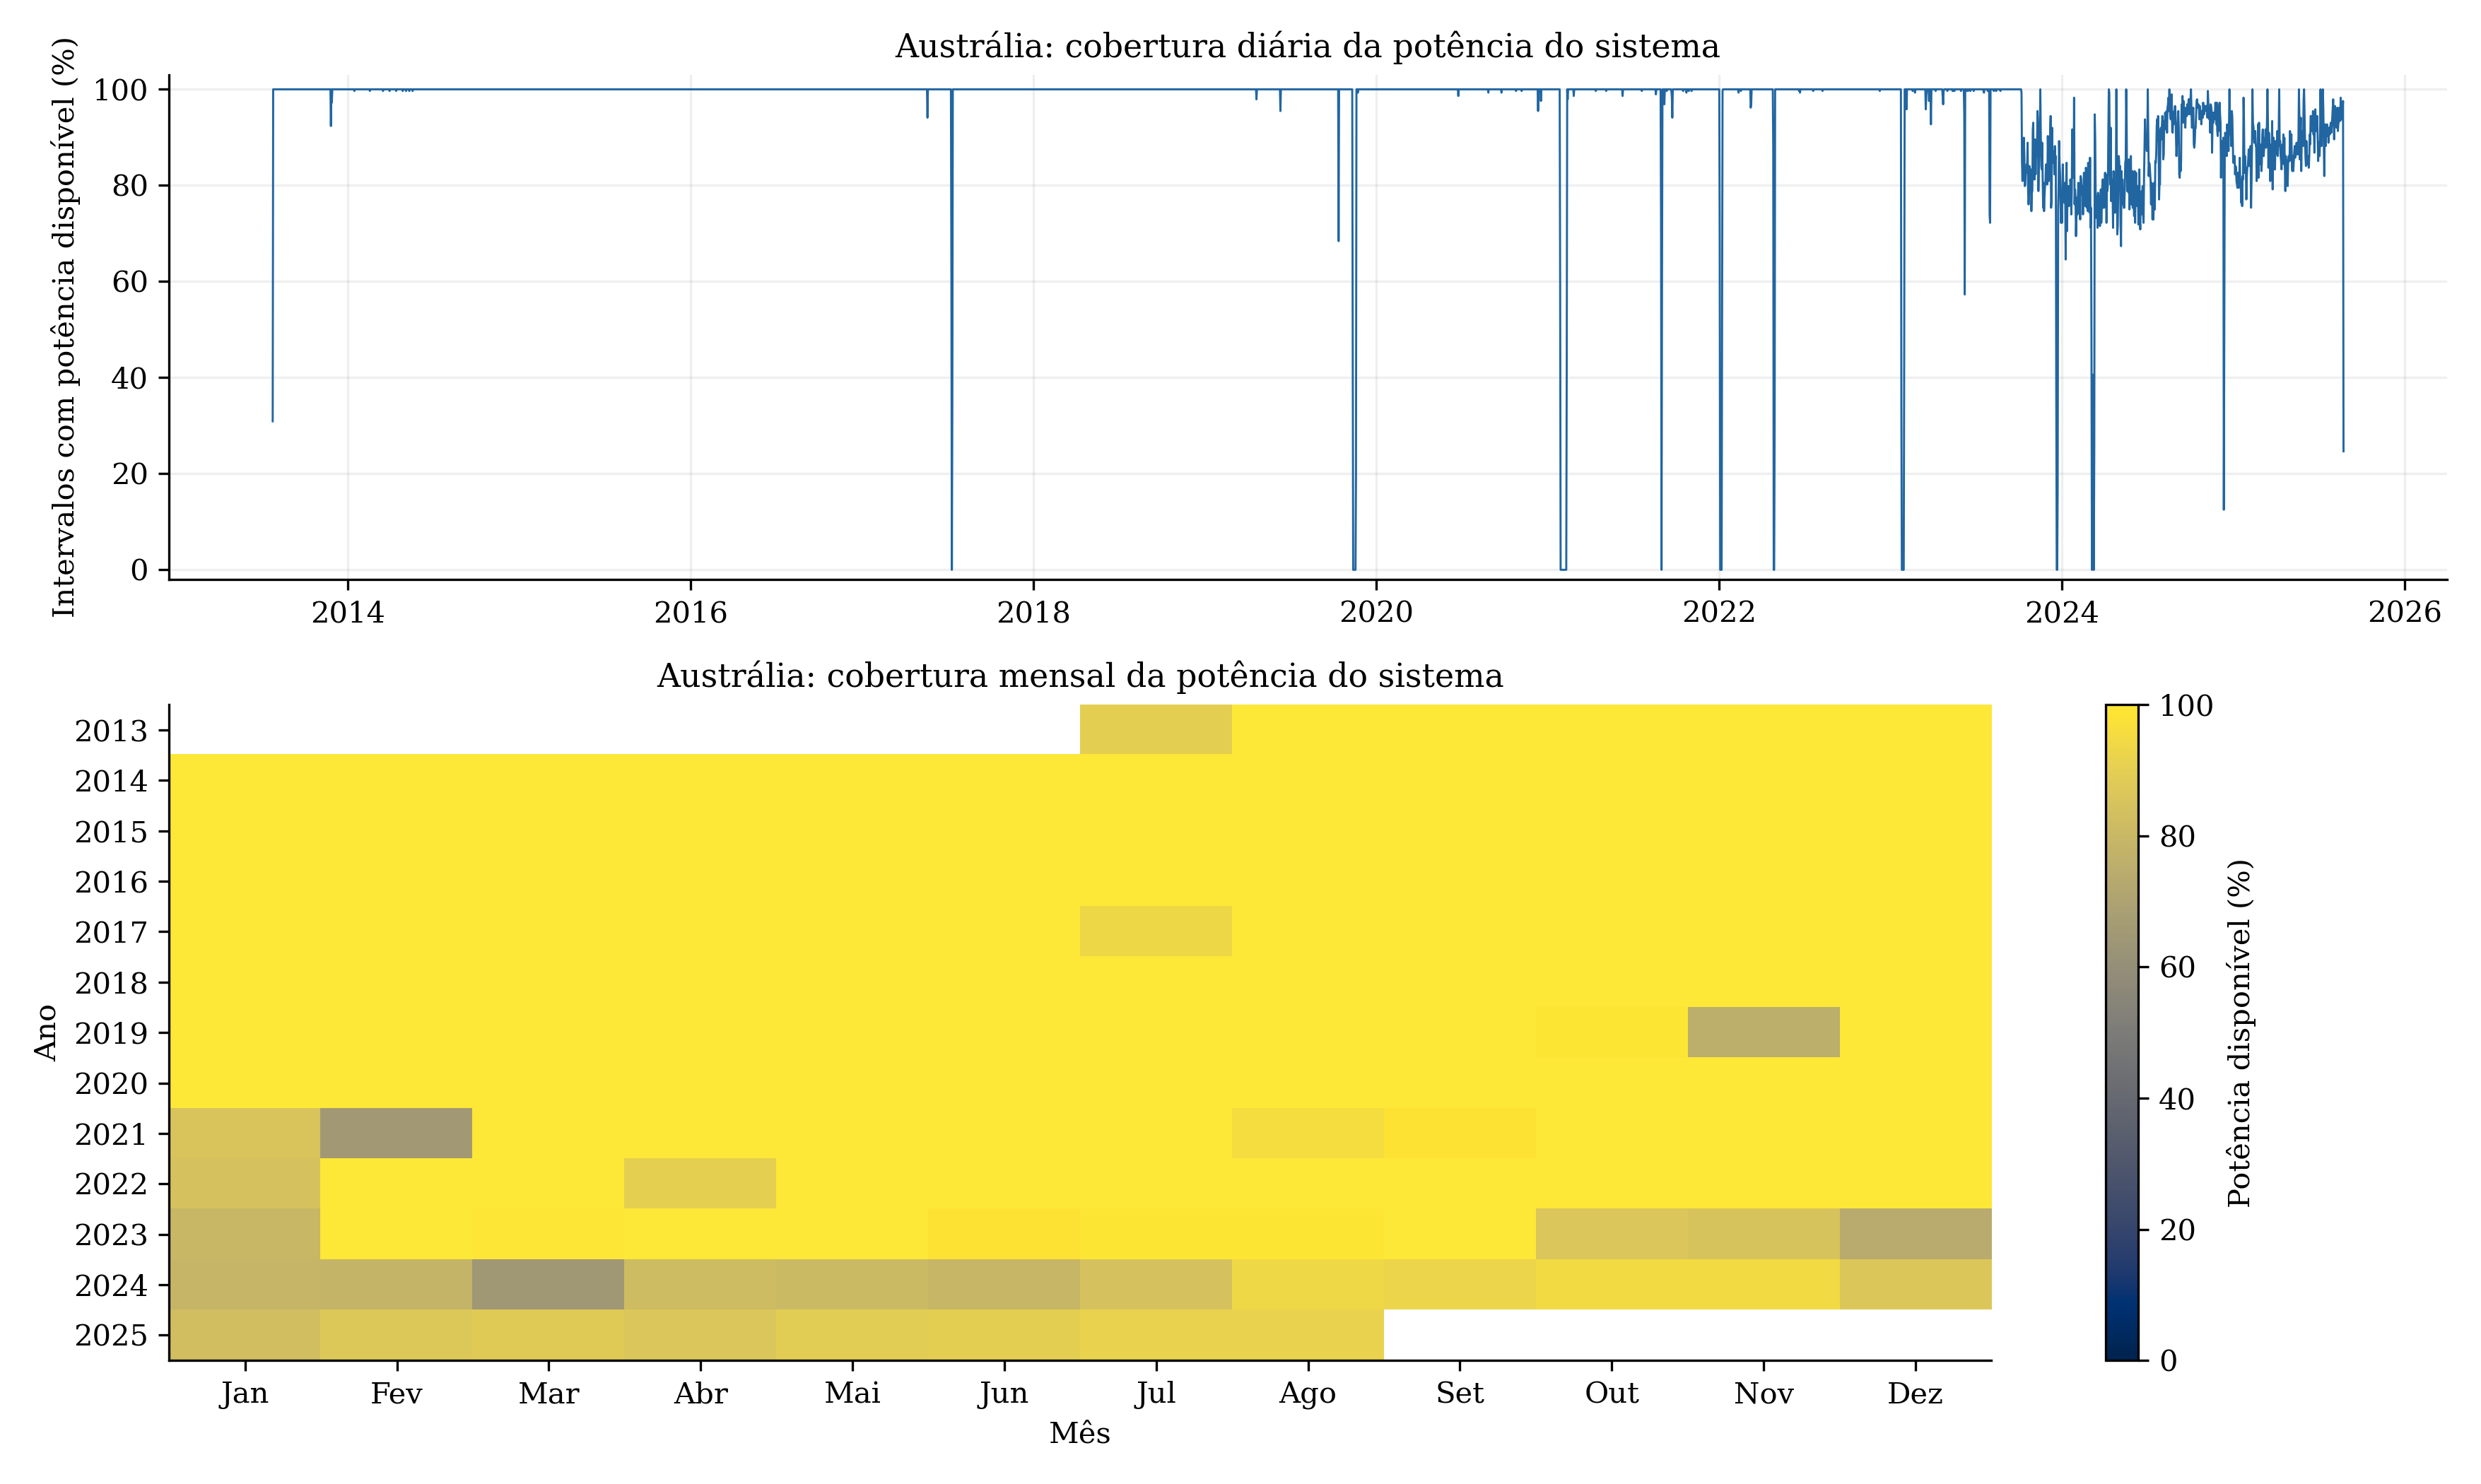

**Figura 3.2-01: Cobertura temporal da potência do sistema: Austrália.** Proporção de intervalos de cinco minutos com potência numérica finita, considerando 288 intervalos esperados por dia. Os dois painéis representam exclusivamente potência; zeros observados são contabilizados como disponíveis. A variável australiana é Active_Power; o período integral do arquivo é apresentado, enquanto o experimento diário utiliza somente dados até 2023. Regiões em branco representam meses externos ao período analisado.

Fonte: elaboração própria a partir das bases analisadas.

In [2]:
display(tabelas["resumo_fontes"].query("fonte == 'australia'"))
display(fontes["australia"]["estatisticas"][["variavel", "significado_pt", "unidade", "intervalos_esperados", "intervalos_disponiveis", "cobertura_pct"]])
figura(1)


## 3.2.2 Base de dados brasileira

A fonte é `Leopoldo_base_consolidada_5min.csv`, gerada pelo `data.ipynb` com uma grade completa de cinco minutos para `07-07FX` em 2025. `datetime` está em UTC e é convertido para `America/Sao_Paulo` nesta análise. O 03_02 lê os valores fornecidos, sem refazer o merge ou executar seu gerador.

No gerador, a grade completa é a tabela principal. Estação e inversores são associados separadamente, de modo que faltar uma fonte não elimina dados da outra. A seleção de duplicatas e a soma com `min_count=1` foram preservadas; os indicadores de presença e a quantidade de inversores foram adicionados.

A potência utiliza `total_active_power_w` dividida por 1000, em kW. A análise mantém os 55 canais físicos da estação, inclusive canais vazios, sem ERA5 ou correção de escala. As contagens atualizadas de potência completa e parcial constam da auditoria abaixo.


In [3]:
display(tabelas["resumo_fontes"].query("fonte == 'brasil'"))
display(tabelas["auditoria_csv_brasil"])
display(fontes["brasil"]["estatisticas"][["variavel", "significado_pt", "unidade", "intervalos_esperados", "intervalos_disponiveis", "cobertura_pct"]])


,fonte,variavel_potencia,inicio,fim,intervalos_esperados,intervalos_com_potencia,cobertura_potencia_pct,variaveis_meteorologicas
1,brasil,potencia_total_kw,2025-01-01 00:00:00,2025-12-31 23:55:00,105120,84235,80.132,55


,linhas_csv,linhas_usina_no_ano,ano,usina,inicio_utc,fim_utc,inicio_local,fim_local,intervalos_calendario,horarios_duplicados,horarios_desalinhados,intervalos_com_potencia,regra_presenca,regra_merge_documentada,contribuintes,intervalos_oito_inversores,intervalos_soma_parcial
0,105120,105120,2025,07-07FX,2025-01-01 03:00:00+00:00,2026-01-01 02:55:00+00:00,2025-01-01 00:00:00,2025-12-31 23:55:00,105120,0,0,84235,Indicadores tem_registro_estacao e tem_registr...,data.ipynb usa a grade completa de cinco minut...,n_inversores_potencia distingue somas completa...,82787,1448


,variavel,significado_pt,unidade,intervalos_esperados,intervalos_disponiveis,cobertura_pct
0,potencia_total_kw,Potência agregada informada em total_active_po...,kW (W do CSV divididos por 1000),105120,84235,80.132
1,indice_albedo_medio,Índice de albedo medio,"adimensional, a confirmar",105120,0,0.000
2,gri_kwh_day_est,Irradiação do canal GRI (plano/componente a co...,"kWh/m², a confirmar",105120,62,0.059
3,albedo_tracker,Albedo associado ao rastreador solar,"adimensional, a confirmar",105120,62,0.059
4,gri_irr_med,Irradiância do canal GRI (plano/componente a c...,unidade e escala a confirmar,105120,62,0.059
5,poa_kwh_hour,"Irradiação no plano dos módulos, horária","kWh/m², a confirmar",105120,33383,31.757
6,precipitacao_acc,Precipitação acumulada,"mm, a confirmar",105120,33383,31.757
7,dir_vento,Direção do vento,"graus, a confirmar",105120,33383,31.757
8,poa_irradiancia,Irradiância no plano dos módulos,unidade e escala a confirmar,105120,33383,31.757
9,poa_irr_med,"Irradiância no plano dos módulos, média",unidade e escala a confirmar,105120,33383,31.757


### Cobertura diária e mensal da potência brasileira

A figura abaixo apresenta exclusivamente a disponibilidade de potência agregada em `total_active_power_w`, na base `Leopoldo_base_consolidada_5min.csv`. O painel superior mostra a proporção diária de intervalos de cinco minutos com potência numérica finita; o painel inferior mostra a cobertura mensal. O denominador considera 288 intervalos por dia no calendário completo de 2025. Zeros observados são considerados disponíveis. A ausência da estação não interfere neste indicador; a quantidade de inversores por soma é informada na auditoria.

A imagem é regenerada pela célula de preparação e exportada em PNG (300 dpi) e PDF: `reports/tcc/caracterizacao_sistemas/figuras/fig_3_2_02_cobertura_brasil`.


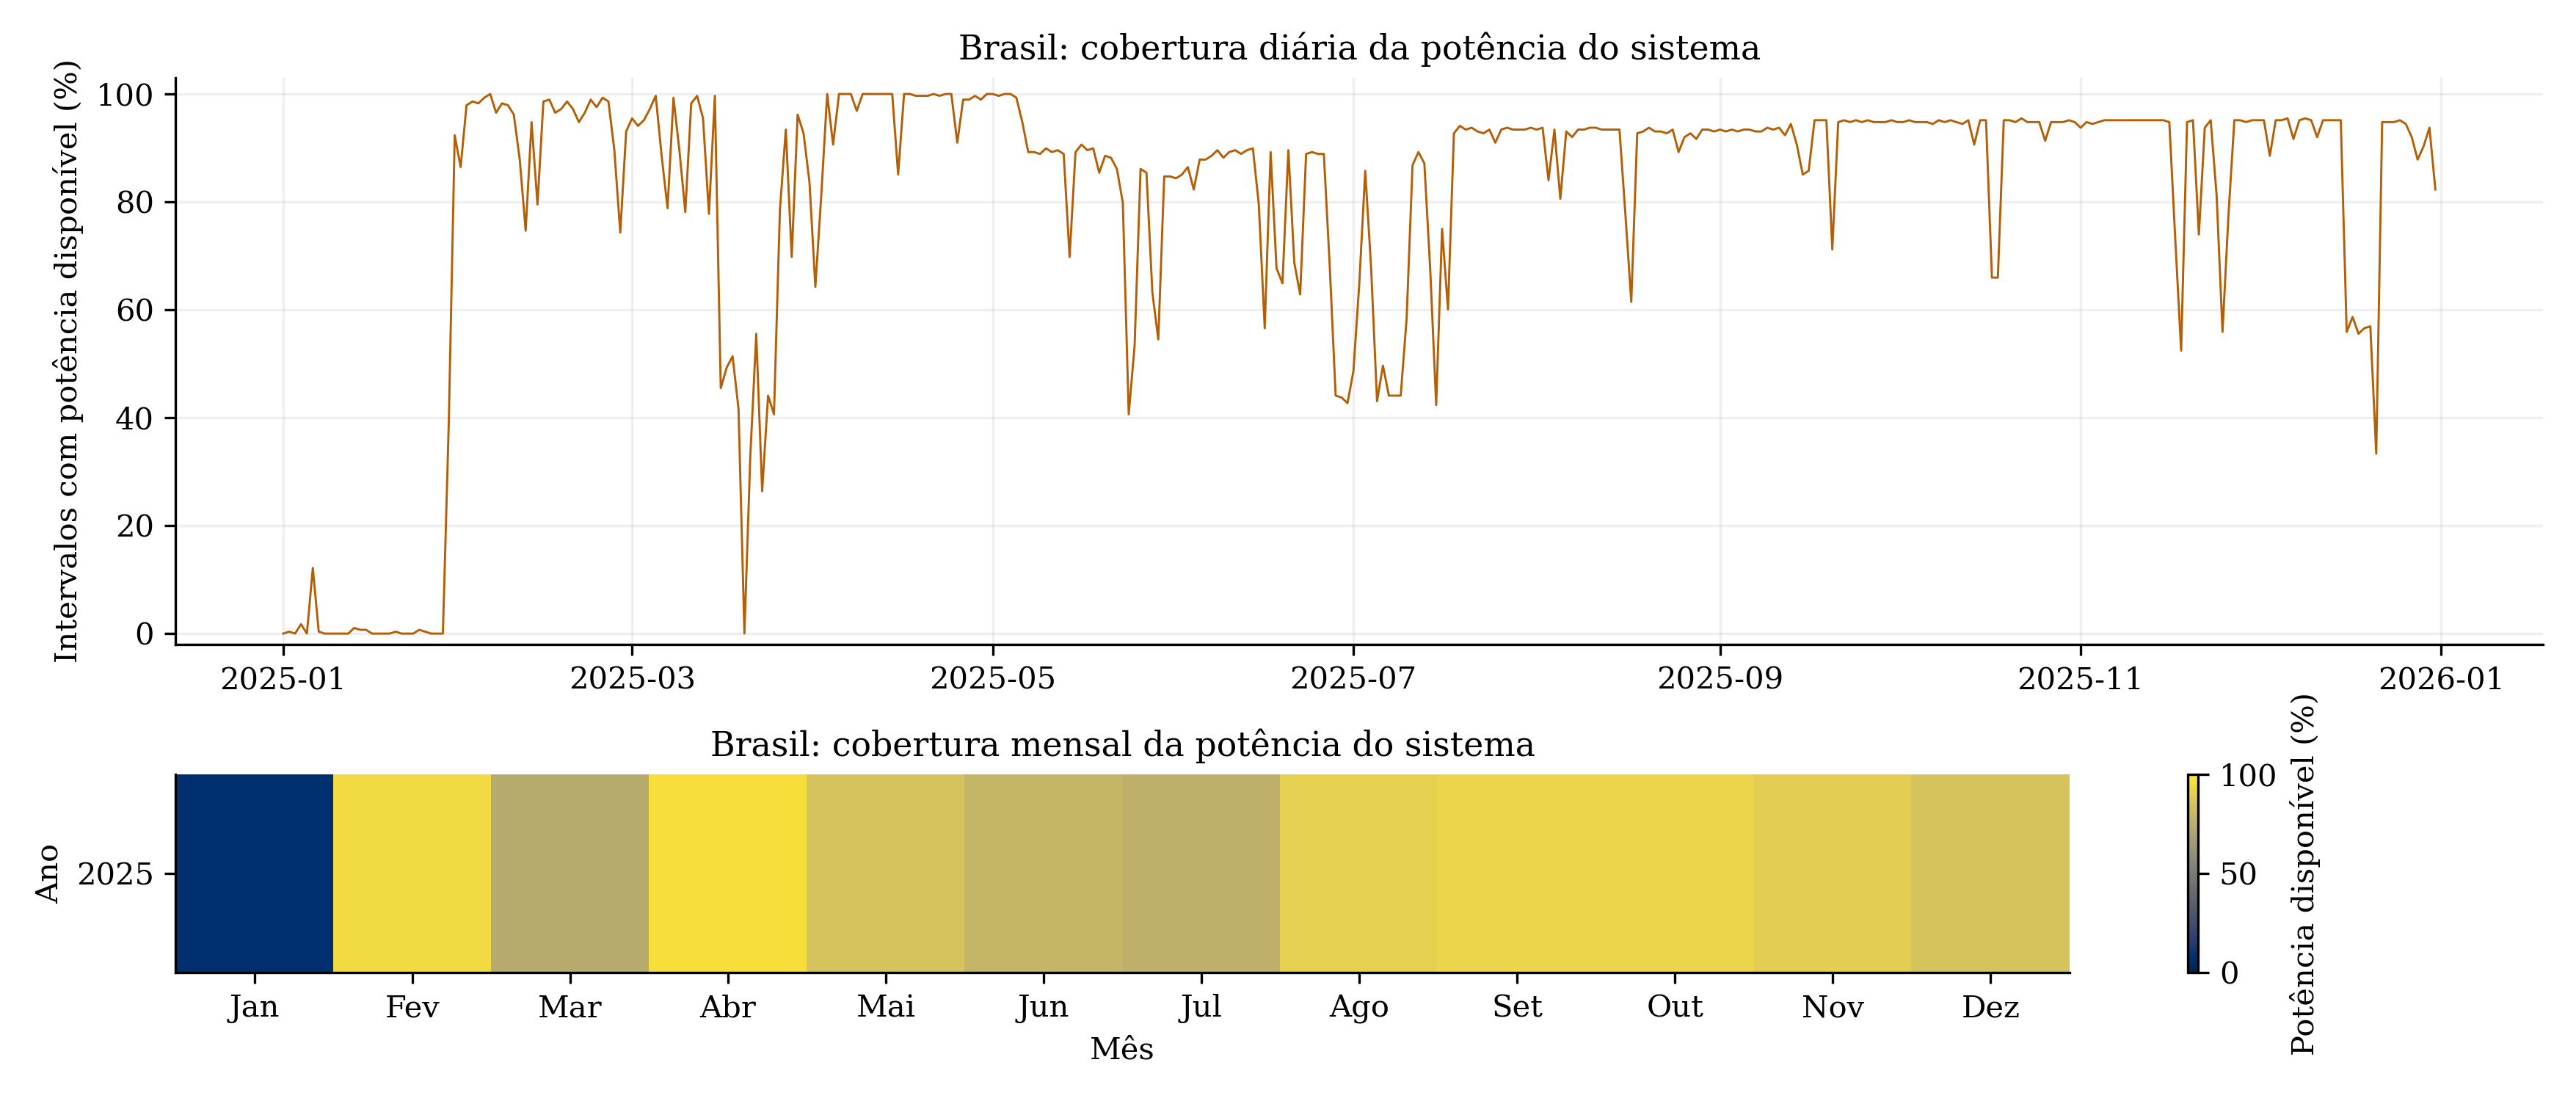

**Figura 3.2-02: Cobertura temporal da potência do sistema: Brasil.** Proporção de intervalos de cinco minutos com potência numérica finita, considerando 288 intervalos esperados por dia. Os dois painéis representam exclusivamente potência; zeros observados são contabilizados como disponíveis. A potência brasileira é a coluna total_active_power_w de Leopoldo_base_consolidada_5min.csv, convertida para kW. O arquivo utiliza uma grade completa e preserva potência mesmo sem meteorologia; n_inversores_potencia identifica somas completas e parciais. A cobertura inclui todas as potências finitas informadas, sem exigir oito contribuintes. Regiões em branco representam meses externos ao período analisado.

Fonte: elaboração própria a partir das bases analisadas.

In [4]:
# Mesmo formato da figura de referência: cobertura diária e mapa mensal.
numero_cobertura_brasil = next(i for i, item in enumerate(indice, start=1)
                               if item["arquivo"] == "fig_3_2_02_cobertura_brasil")
figura(numero_cobertura_brasil, largura=1200)


### Canais da estação solarimétrica

O mapa mensal apresenta todos os canais físicos da estação. Os nomes das colunas foram preservados para rastreabilidade; seus significados em português constam da tabela anterior. Cobertura nula pode corresponder a um campo de esquema sem aquisição, sem demonstrar por si só falha de sensor. A escala do GHI e os canais GRI permanecem sujeitos à confirmação documental.


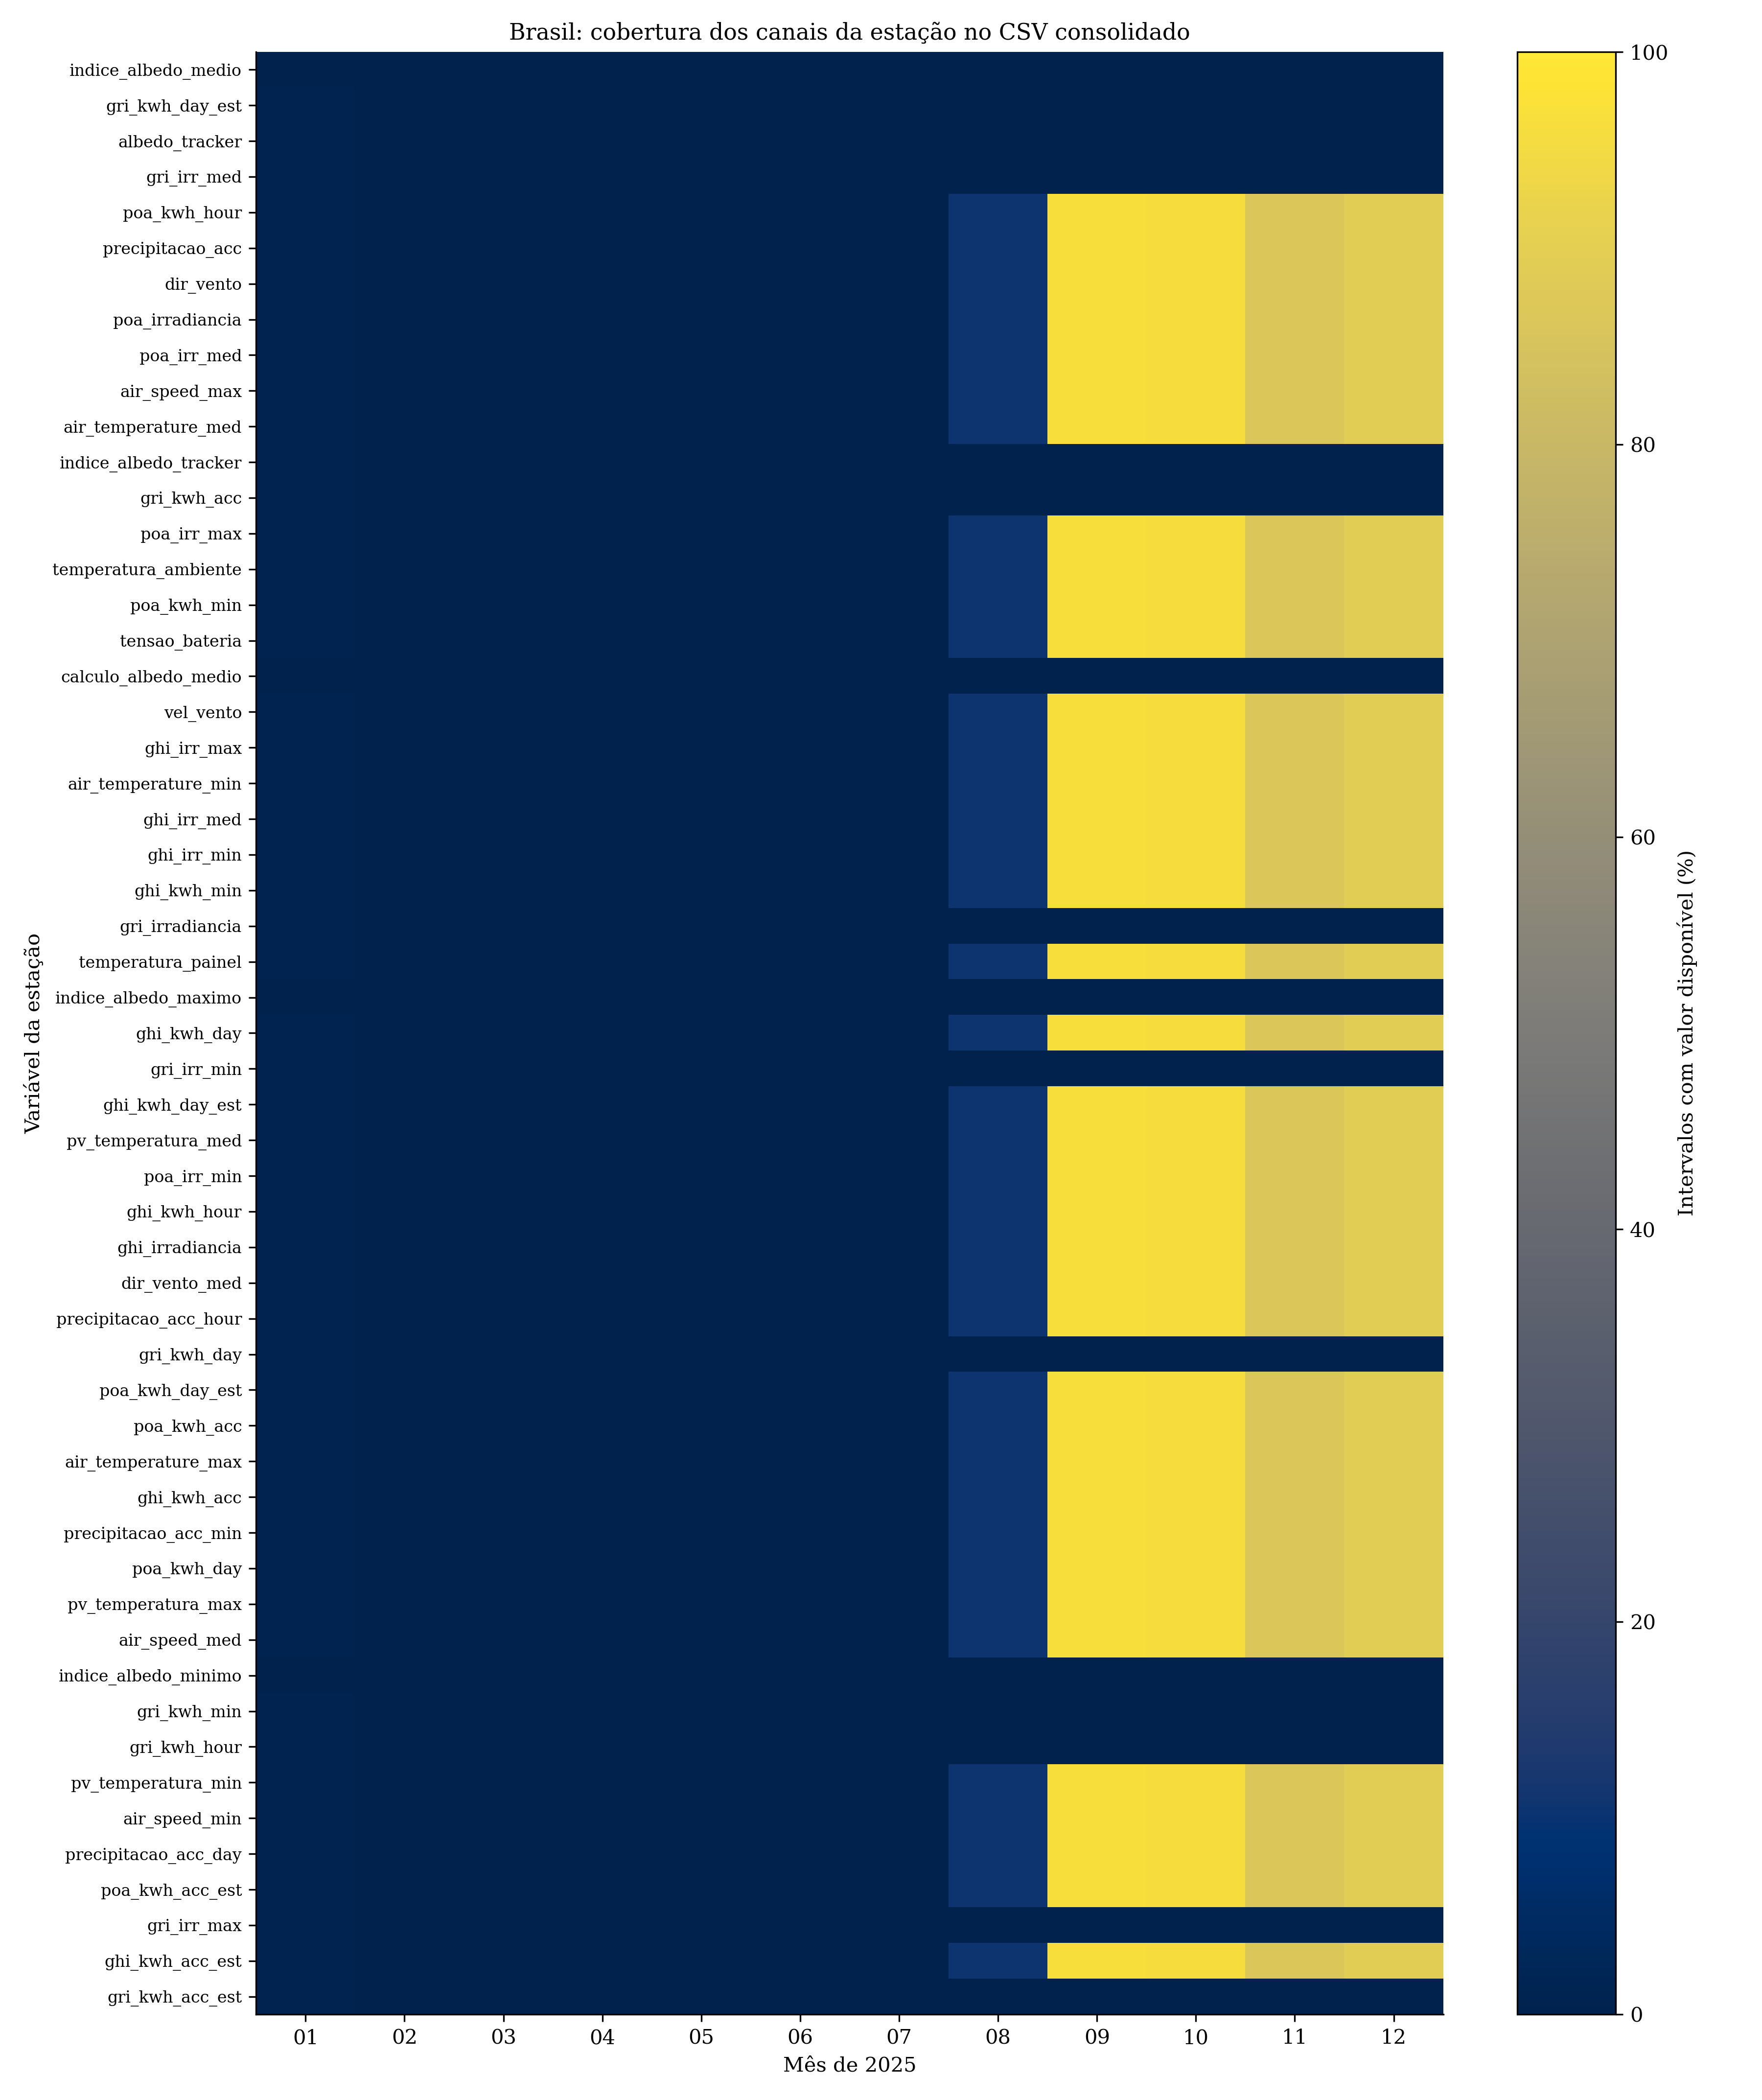

**Figura 3.2-03: Cobertura mensal dos canais da estação solarimétrica brasileira.** Proporção de intervalos do calendário completo de 2025 com valor numérico finito em cada canal físico da estação, utilizando exclusivamente Leopoldo_base_consolidada_5min.csv. Os valores são lidos sem nova consolidação ou imputação. Cada variável possui contagem independente. Canais totalmente ausentes são preservados no inventário; sua ausência não comprova falha de sensor. Nenhuma variável ERA5 é incluída.

Fonte: elaboração própria a partir das bases analisadas.

In [5]:
figura(3)


## 3.2.3 Análise descritiva e disponibilidade dos dados

As estatísticas são calculadas sobre os valores numéricos finitos de cada variável, após o alinhamento, preservando zeros e valores sinalizados. A potência dos dois sistemas é expressa em kW; as capacidades e os períodos de observação diferem. A meteorologia é apresentada em suas unidades originais, com as pendências explicitadas no dicionário.


,fonte,variavel,unidade,intervalos_disponiveis,media,desvio_padrao,minimo,q25,mediana,q75,maximo
0,Austrália,Active_Power,kW,1229605,4.278,5.959,-0.062,0.000,0.000,8.079,23.426
1,Austrália,Wind_Speed,a confirmar,340915,2.280,3.368,-919.534,1.089,2.011,3.311,54.389
2,Austrália,Weather_Temperature_Celsius,°C,1224057,21.185,10.081,-39.988,14.527,21.777,28.421,61.924
3,Austrália,Weather_Relative_Humidity,%,1224066,36.904,23.647,0.000,18.372,30.405,51.378,131.158
4,Austrália,Global_Horizontal_Radiation,W/m²,1224105,264.931,364.322,-985.690,2.329,7.293,530.003,2015.182
5,Austrália,Diffuse_Horizontal_Radiation,"W/m², a confirmar",1224105,54.422,90.752,0.000,1.283,5.897,73.163,801.232
6,Austrália,Wind_Direction,"graus, a confirmar",1224111,93.492,171.955,-19837.791,31.627,41.951,140.131,30152.340
7,Austrália,Weather_Daily_Rainfall,"mm, a confirmar",1224114,0.306,2.113,0.000,0.000,0.000,0.000,66.000
8,Austrália,Radiation_Global_Tilted,"W/m², a confirmar",1106080,285.522,383.341,-0.012,2.810,8.620,579.969,1553.391
9,Austrália,Radiation_Diffuse_Tilted,"W/m², a confirmar",1148207,57.537,183.157,-0.019,1.540,3.717,80.519,97322.586


,fonte,variavel,unidade,intervalos_disponiveis,media,desvio_padrao,minimo,q25,mediana,q75,maximo
0,Brasil: CSV consolidado,potencia_total_kw,kW (W do CSV divididos por 1000),84235,250.057,348.565,0.000,0.000,2.157,486.401,1009.112
1,Brasil: CSV consolidado,indice_albedo_medio,"adimensional, a confirmar",0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Brasil: CSV consolidado,gri_kwh_day_est,"kWh/m², a confirmar",62,0.045,0.146,0.000,0.000,0.000,0.000,0.610
3,Brasil: CSV consolidado,albedo_tracker,"adimensional, a confirmar",62,-0.022,0.266,-2.045,0.000,0.000,0.000,0.347
4,Brasil: CSV consolidado,gri_irr_med,unidade e escala a confirmar,62,4.658,18.922,-0.574,0.000,0.000,0.000,98.833
5,Brasil: CSV consolidado,poa_kwh_hour,"kWh/m², a confirmar",33383,0.239,0.331,-0.006,-0.002,0.013,0.449,1.190
6,Brasil: CSV consolidado,precipitacao_acc,"mm, a confirmar",33383,0.853,1.877,0.000,0.000,0.000,0.000,7.800
7,Brasil: CSV consolidado,dir_vento,"graus, a confirmar",33383,360.000,0.000,360.000,360.000,360.000,360.000,360.000
8,Brasil: CSV consolidado,poa_irradiancia,unidade e escala a confirmar,33383,240.865,356.205,-14.160,-1.960,8.690,391.290,1572.870
9,Brasil: CSV consolidado,poa_irr_med,unidade e escala a confirmar,33383,240.918,354.561,-16.462,-1.964,8.641,397.282,1502.971


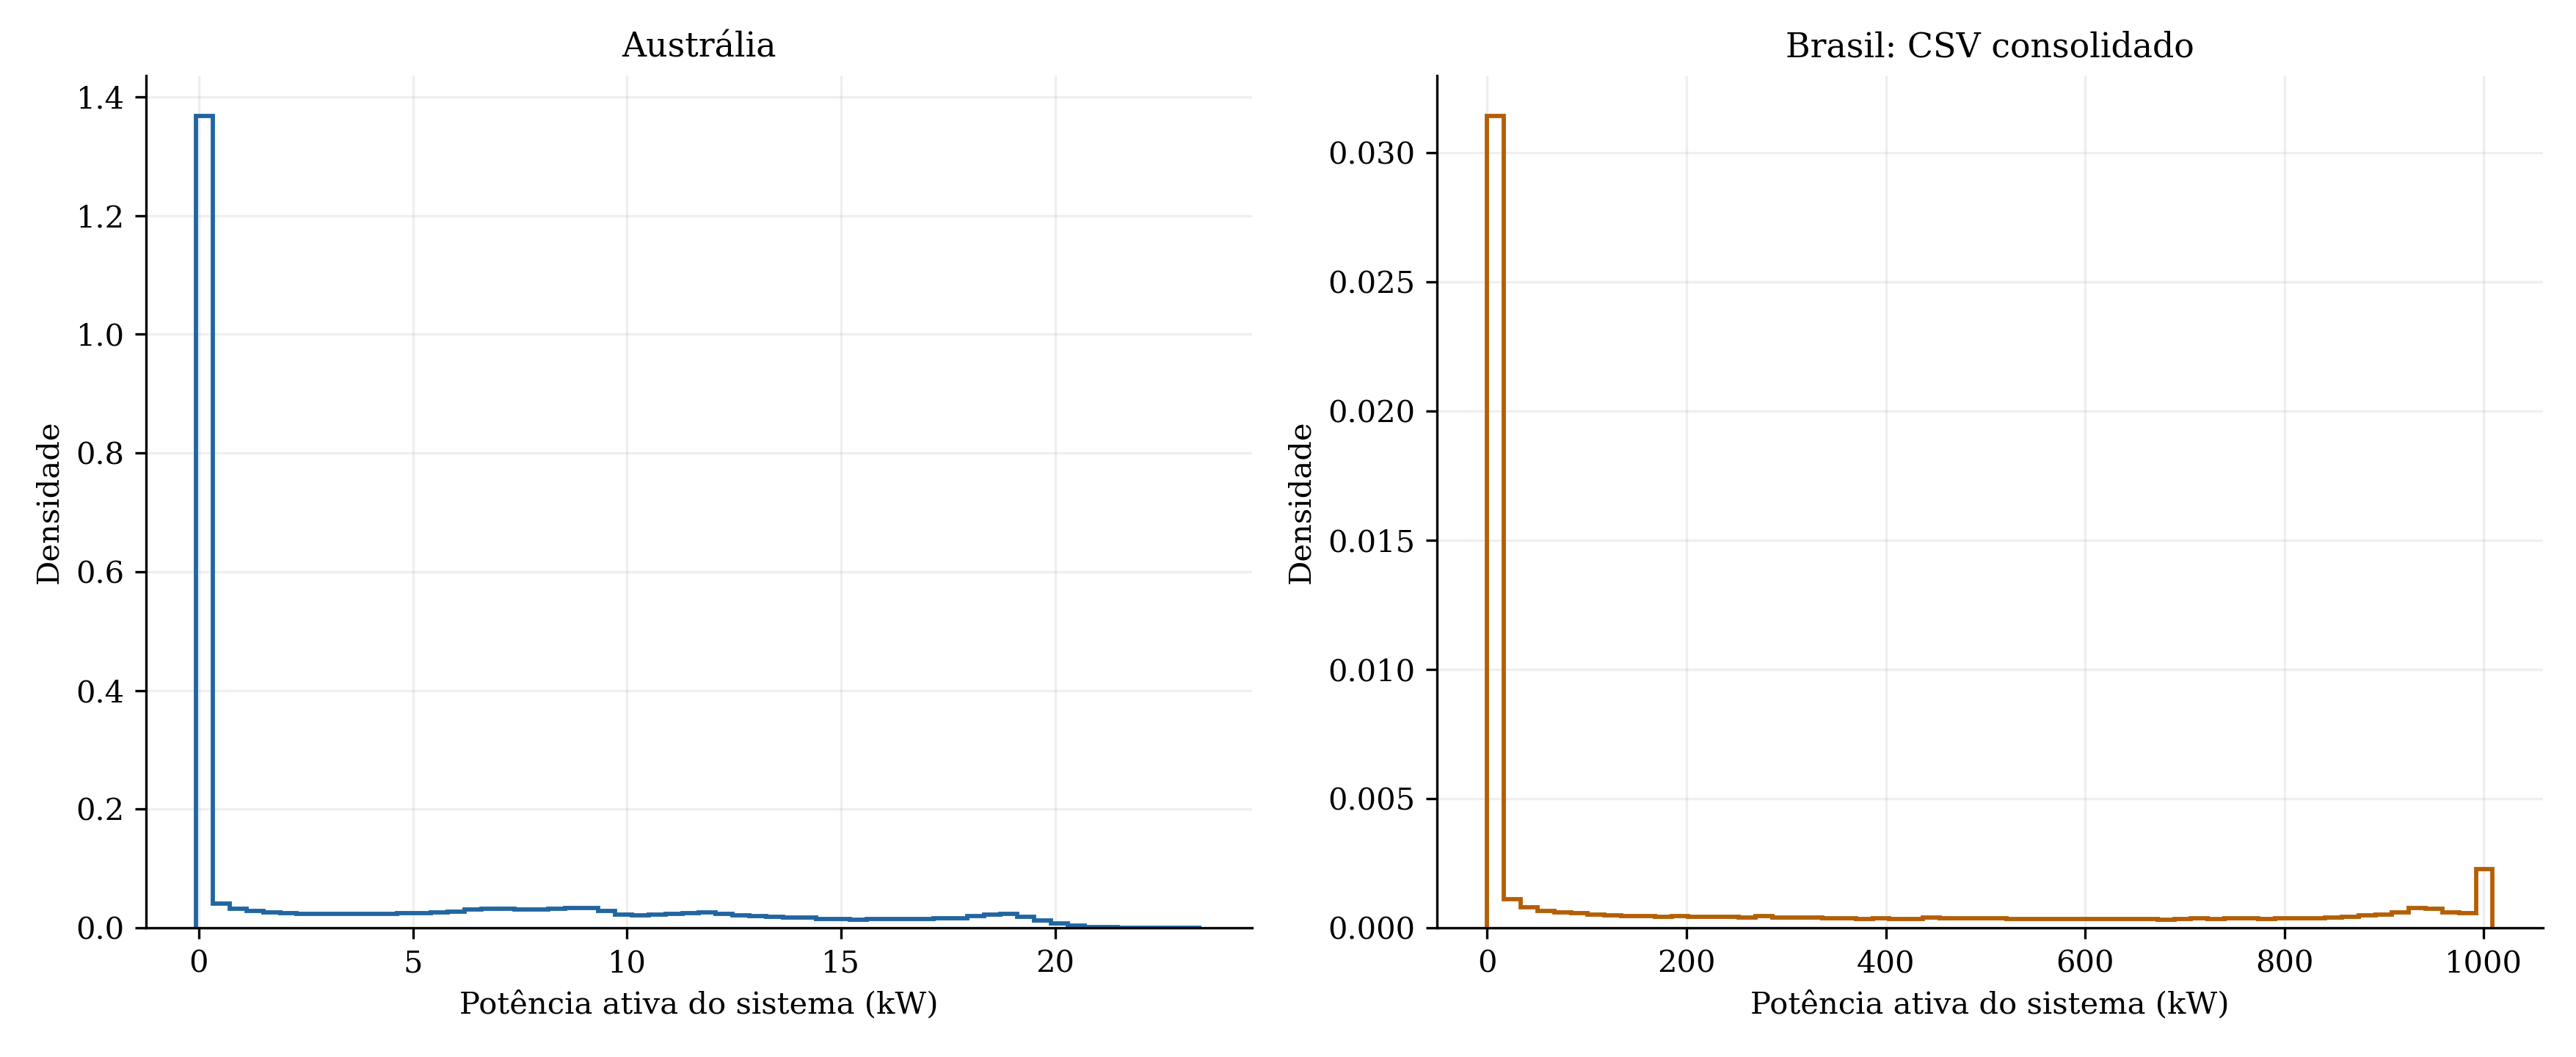

**Figura 3.2-04: Distribuições de potência dos sistemas australiano e brasileiro.** Histogramas de densidade da potência em kW, utilizando todos os intervalos disponíveis, inclusive zeros e valores negativos finitos. No Brasil, utiliza-se a potência agregada informada no CSV consolidado manual, sem exigir novamente oito contribuintes ou refazer as somas. As escalas de potência e os períodos de observação diferem entre os sistemas; não se aplica normalização por capacidade nesta etapa.

Fonte: elaboração própria a partir das bases analisadas.

In [6]:
colunas = ["fonte", "variavel", "unidade", "intervalos_disponiveis", "media", "desvio_padrao", "minimo", "q25", "mediana", "q75", "maximo"]
for chave in ["australia", "brasil"]:
    display(fontes[chave]["estatisticas"][colunas])
figura(4)


### Disponibilidade individual das variáveis

A cobertura temporal considera todos os intervalos do calendário completo. A presença de cada fonte é identificada pelos seus próprios indicadores, pois a existência de uma linha na grade não comprova aquisição de dados. As tabelas abrangem todas as variáveis selecionadas; a figura apresenta um subconjunto.


AUSTRALIA
BRASIL


,variavel,intervalos_esperados,intervalos_sem_registro,registro_sem_valor_disponivel,intervalos_disponiveis,cobertura_pct,preenchimento_nos_intervalos_com_registro_pct
0,Active_Power,1270944,14513,26826,1229605,96.747,97.865
1,Wind_Speed,1270944,14513,915516,340915,26.824,27.134
2,Weather_Temperature_Celsius,1270944,14513,32374,1224057,96.311,97.423
3,Weather_Relative_Humidity,1270944,14513,32365,1224066,96.312,97.424
4,Global_Horizontal_Radiation,1270944,14513,32326,1224105,96.315,97.427
5,Diffuse_Horizontal_Radiation,1270944,14513,32326,1224105,96.315,97.427
6,Wind_Direction,1270944,14513,32320,1224111,96.315,97.428
7,Weather_Daily_Rainfall,1270944,14513,32317,1224114,96.315,97.428
8,Radiation_Global_Tilted,1270944,14513,150351,1106080,87.028,88.033
9,Radiation_Diffuse_Tilted,1270944,14513,108224,1148207,90.343,91.386


,variavel,intervalos_esperados,intervalos_sem_registro,registro_sem_valor_disponivel,intervalos_disponiveis,cobertura_pct,preenchimento_nos_intervalos_com_registro_pct
0,potencia_total_kw,105120,20885,0,84235,80.132,100.000
1,indice_albedo_medio,105120,71737,33383,0,0.000,0.000
2,gri_kwh_day_est,105120,71737,33321,62,0.059,0.186
3,albedo_tracker,105120,71737,33321,62,0.059,0.186
4,gri_irr_med,105120,71737,33321,62,0.059,0.186
5,poa_kwh_hour,105120,71737,0,33383,31.757,100.000
6,precipitacao_acc,105120,71737,0,33383,31.757,100.000
7,dir_vento,105120,71737,0,33383,31.757,100.000
8,poa_irradiancia,105120,71737,0,33383,31.757,100.000
9,poa_irr_med,105120,71737,0,33383,31.757,100.000


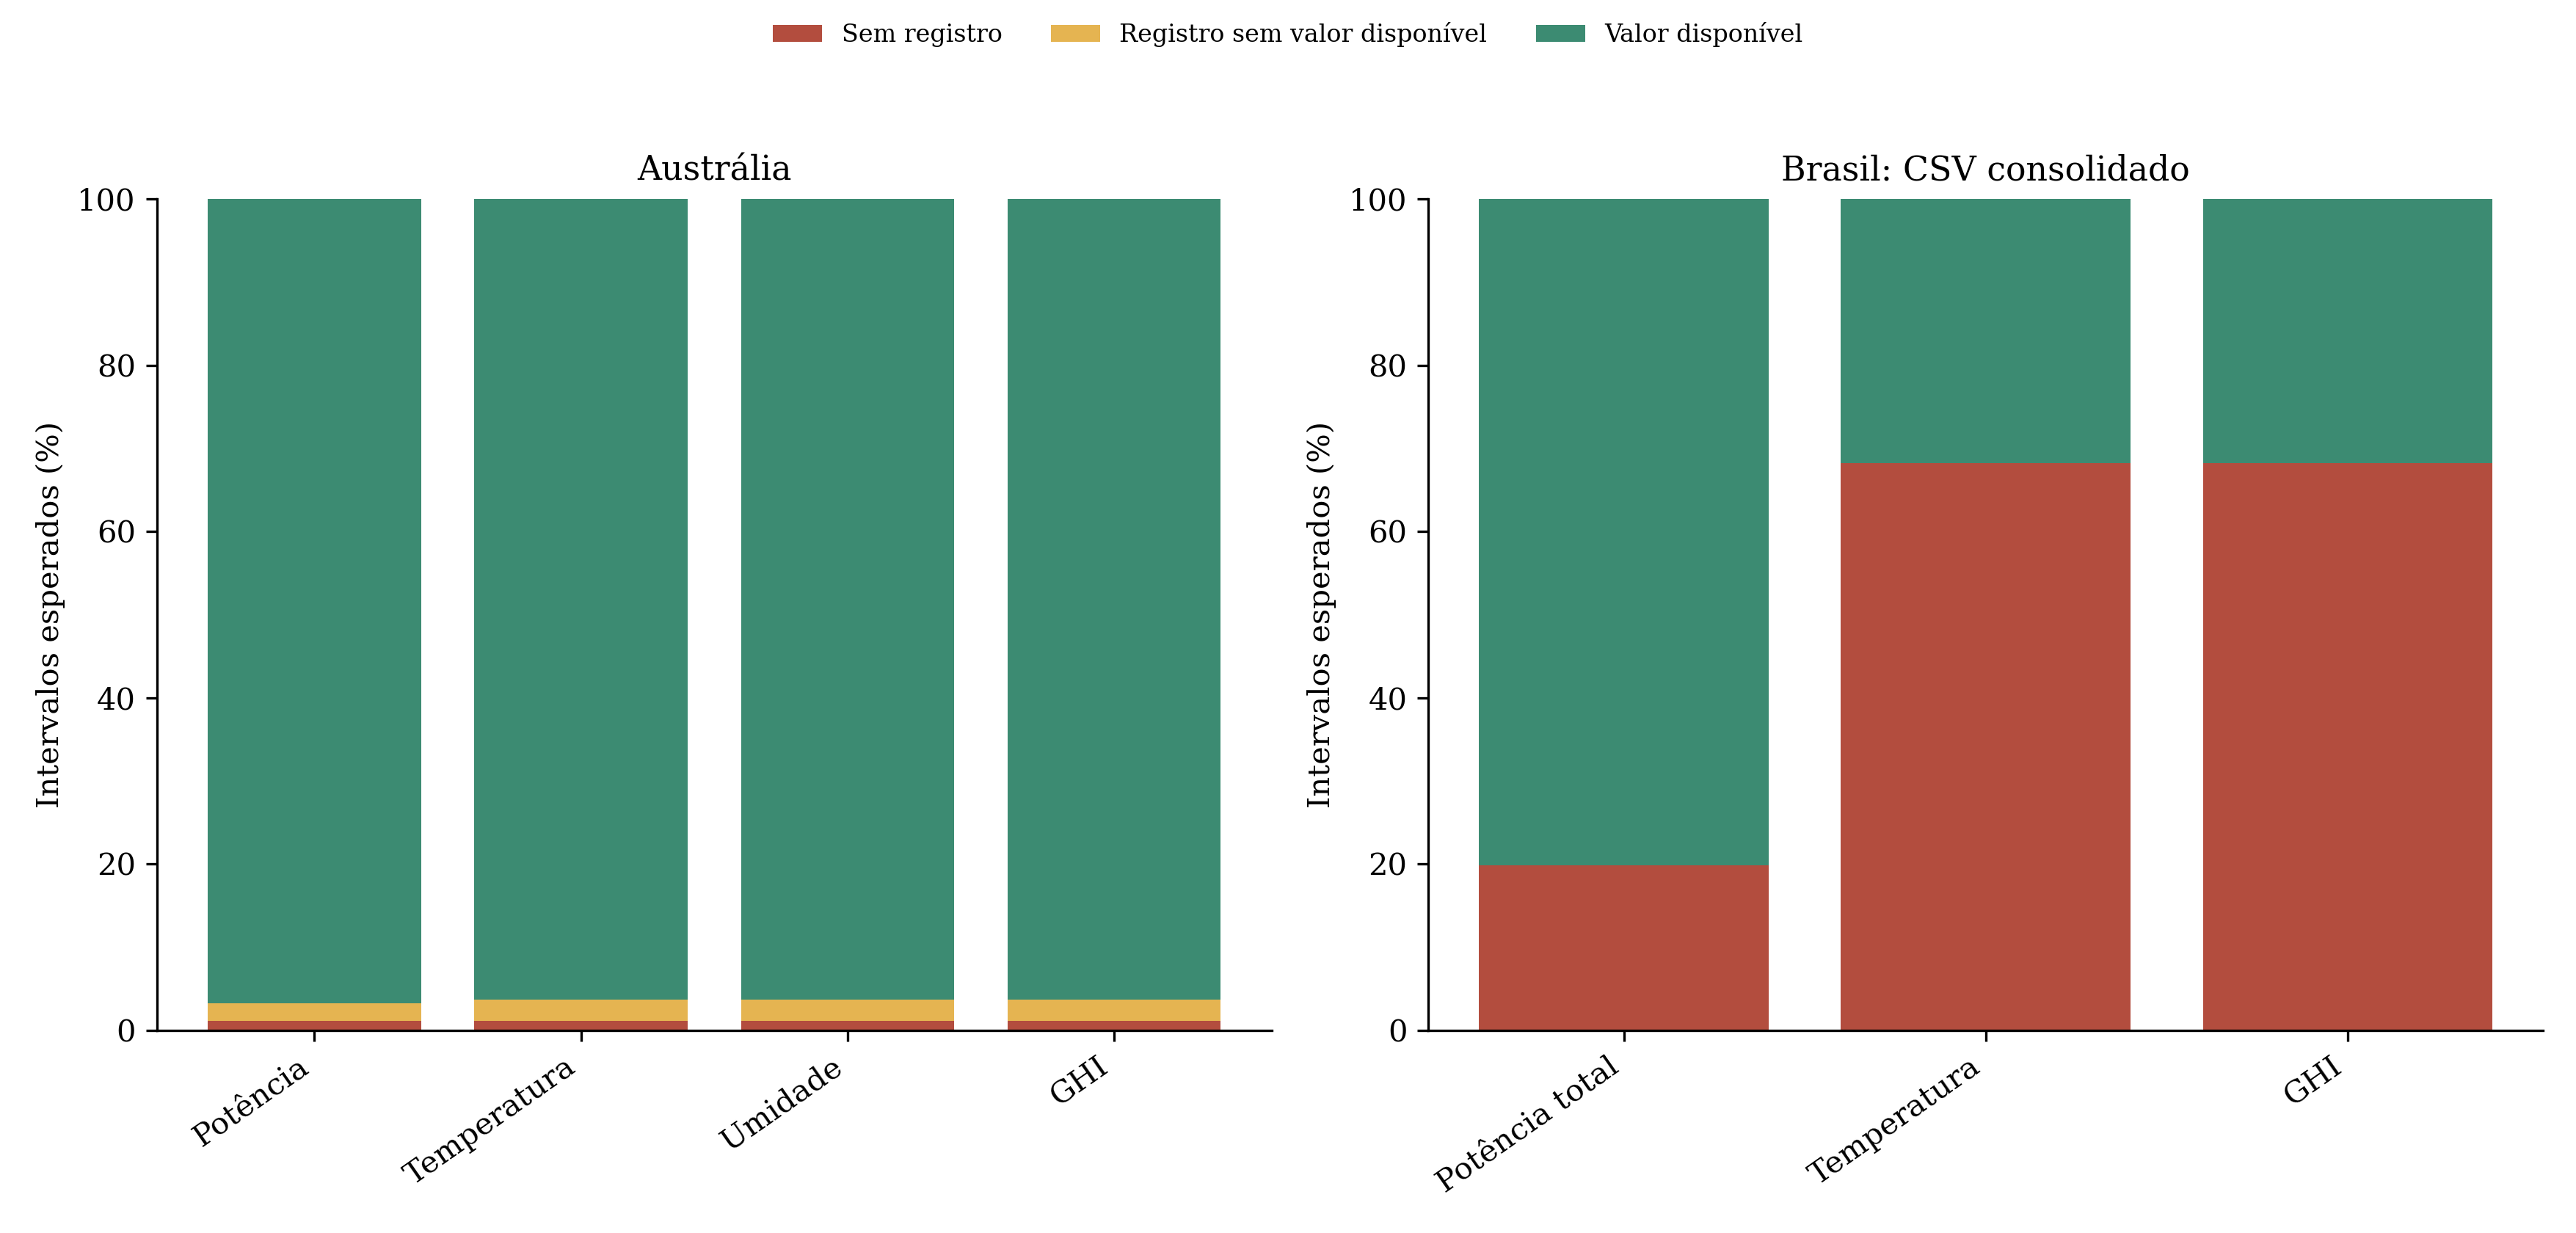

**Figura 3.2-05: Disponibilidade da potência e de variáveis meteorológicas selecionadas.** Distribuição dos intervalos esperados entre ausência de registro da fonte, registro presente sem valor disponível e presença de valor numérico finito. No Brasil, os indicadores tem_registro_inversores e tem_registro_estacao identificam a presença de cada fonte independentemente das linhas da grade completa. As tabelas apresentam todos os canais meteorológicos; a figura seleciona temperatura, umidade disponível na Austrália e GHI.

Fonte: elaboração própria a partir das bases analisadas.

In [7]:
campos = ["variavel", "intervalos_esperados", "intervalos_sem_registro", "registro_sem_valor_disponivel", "intervalos_disponiveis", "cobertura_pct", "preenchimento_nos_intervalos_com_registro_pct"]
for chave in ["australia", "brasil"]:
    print(chave.upper())
    display(fontes[chave]["estatisticas"][campos])
figura(5)


### Períodos com menor cobertura de potência

Cada tabela apresenta os dez dias de menor disponibilidade de potência do respectivo sistema. As tabelas diárias e mensais completas são exportadas para todas as variáveis selecionadas.


In [8]:
for chave in ["australia", "brasil"]:
    alvo = analise["alvos"][chave]
    print(chave.upper(), "variável:", alvo)
    display(fontes[chave]["cobertura_diaria"][[alvo]].nsmallest(10, alvo))


AUSTRALIA variável: Active_Power
BRASIL variável: potencia_total_kw


,Active_Power
horario,
2017-07-11,0.000
2019-11-13,0.000
2019-11-14,0.000
2019-11-15,0.000
2019-11-16,0.000
2019-11-17,0.000
2019-11-18,0.000
2021-01-28,0.000
2021-01-29,0.000


,potencia_total_kw
horario_local,
2025-01-01,0.000
2025-01-03,0.000
2025-01-05,0.000
2025-01-08,0.000
2025-01-09,0.000
2025-01-10,0.000
2025-01-11,0.000
2025-01-12,0.000
2025-01-16,0.000


## 3.2.4 Identificação de dados ausentes e inconsistências

As lacunas de potência são calculadas sobre o calendário completo. No Brasil, a potência existente é preservada mesmo quando falta estação. As ausências restantes correspondem a intervalos sem potência numérica finita no CSV.

Valores negativos e temperaturas do ar fora de −20 a 60 °C são sinalizados para inspeção, sem exclusão automática. Unidades e escalas pendentes permanecem identificadas no dicionário. A auditoria informa também a quantidade de somas completas e parciais de inversores.


,inicio,fim,posicoes,minutos,fonte,variavel
27,2021-01-27 14:10:00,2021-02-10 14:15:00,4034,20170.000,australia,Active_Power
18,2019-11-12 12:05:00,2019-11-19 19:15:00,2103,10515.000,australia,Active_Power
56,2023-01-24 08:05:00,2023-01-30 13:40:00,1796,8980.000,australia,Active_Power
14892,2025-01-07 23:40:00,2025-01-13 09:40:00,1561,7805.000,brasil,potencia_total_kw
14898,2025-01-15 12:25:00,2025-01-20 13:10:00,1450,7250.000,brasil,potencia_total_kw
45,2022-01-02 16:20:00,2022-01-07 11:55:00,1388,6940.000,australia,Active_Power
14899,2025-01-20 13:20:00,2025-01-24 08:25:00,1094,5470.000,brasil,potencia_total_kw
14902,2025-01-25 21:15:00,2025-01-29 14:10:00,1068,5340.000,brasil,potencia_total_kw
2033,2023-12-20 11:20:00,2023-12-23 18:40:00,953,4765.000,australia,Active_Power
4307,2024-03-04 12:00:00,2024-03-07 11:45:00,862,4310.000,australia,Active_Power


,fonte,variavel,criterio,intervalos_sinalizados
0,australia,Active_Power,Valor negativo; inspeção segundo a variável,18675
1,australia,Wind_Speed,Valor negativo; inspeção segundo a variável,6
2,australia,Weather_Temperature_Celsius,Temperatura do ar fora de −20 a 60 °C,3046
3,australia,Weather_Relative_Humidity,Umidade fora de 0 a 100%,14548
4,australia,Global_Horizontal_Radiation,Valor negativo; inspeção segundo a variável,1
6,australia,Wind_Direction,Valor negativo; inspeção segundo a variável,6154
8,australia,Radiation_Global_Tilted,Valor negativo; inspeção segundo a variável,3
9,australia,Radiation_Diffuse_Tilted,Valor negativo; inspeção segundo a variável,1
13,brasil,albedo_tracker,Valor negativo; inspeção segundo a variável,1
14,brasil,gri_irr_med,Valor negativo; inspeção segundo a variável,1


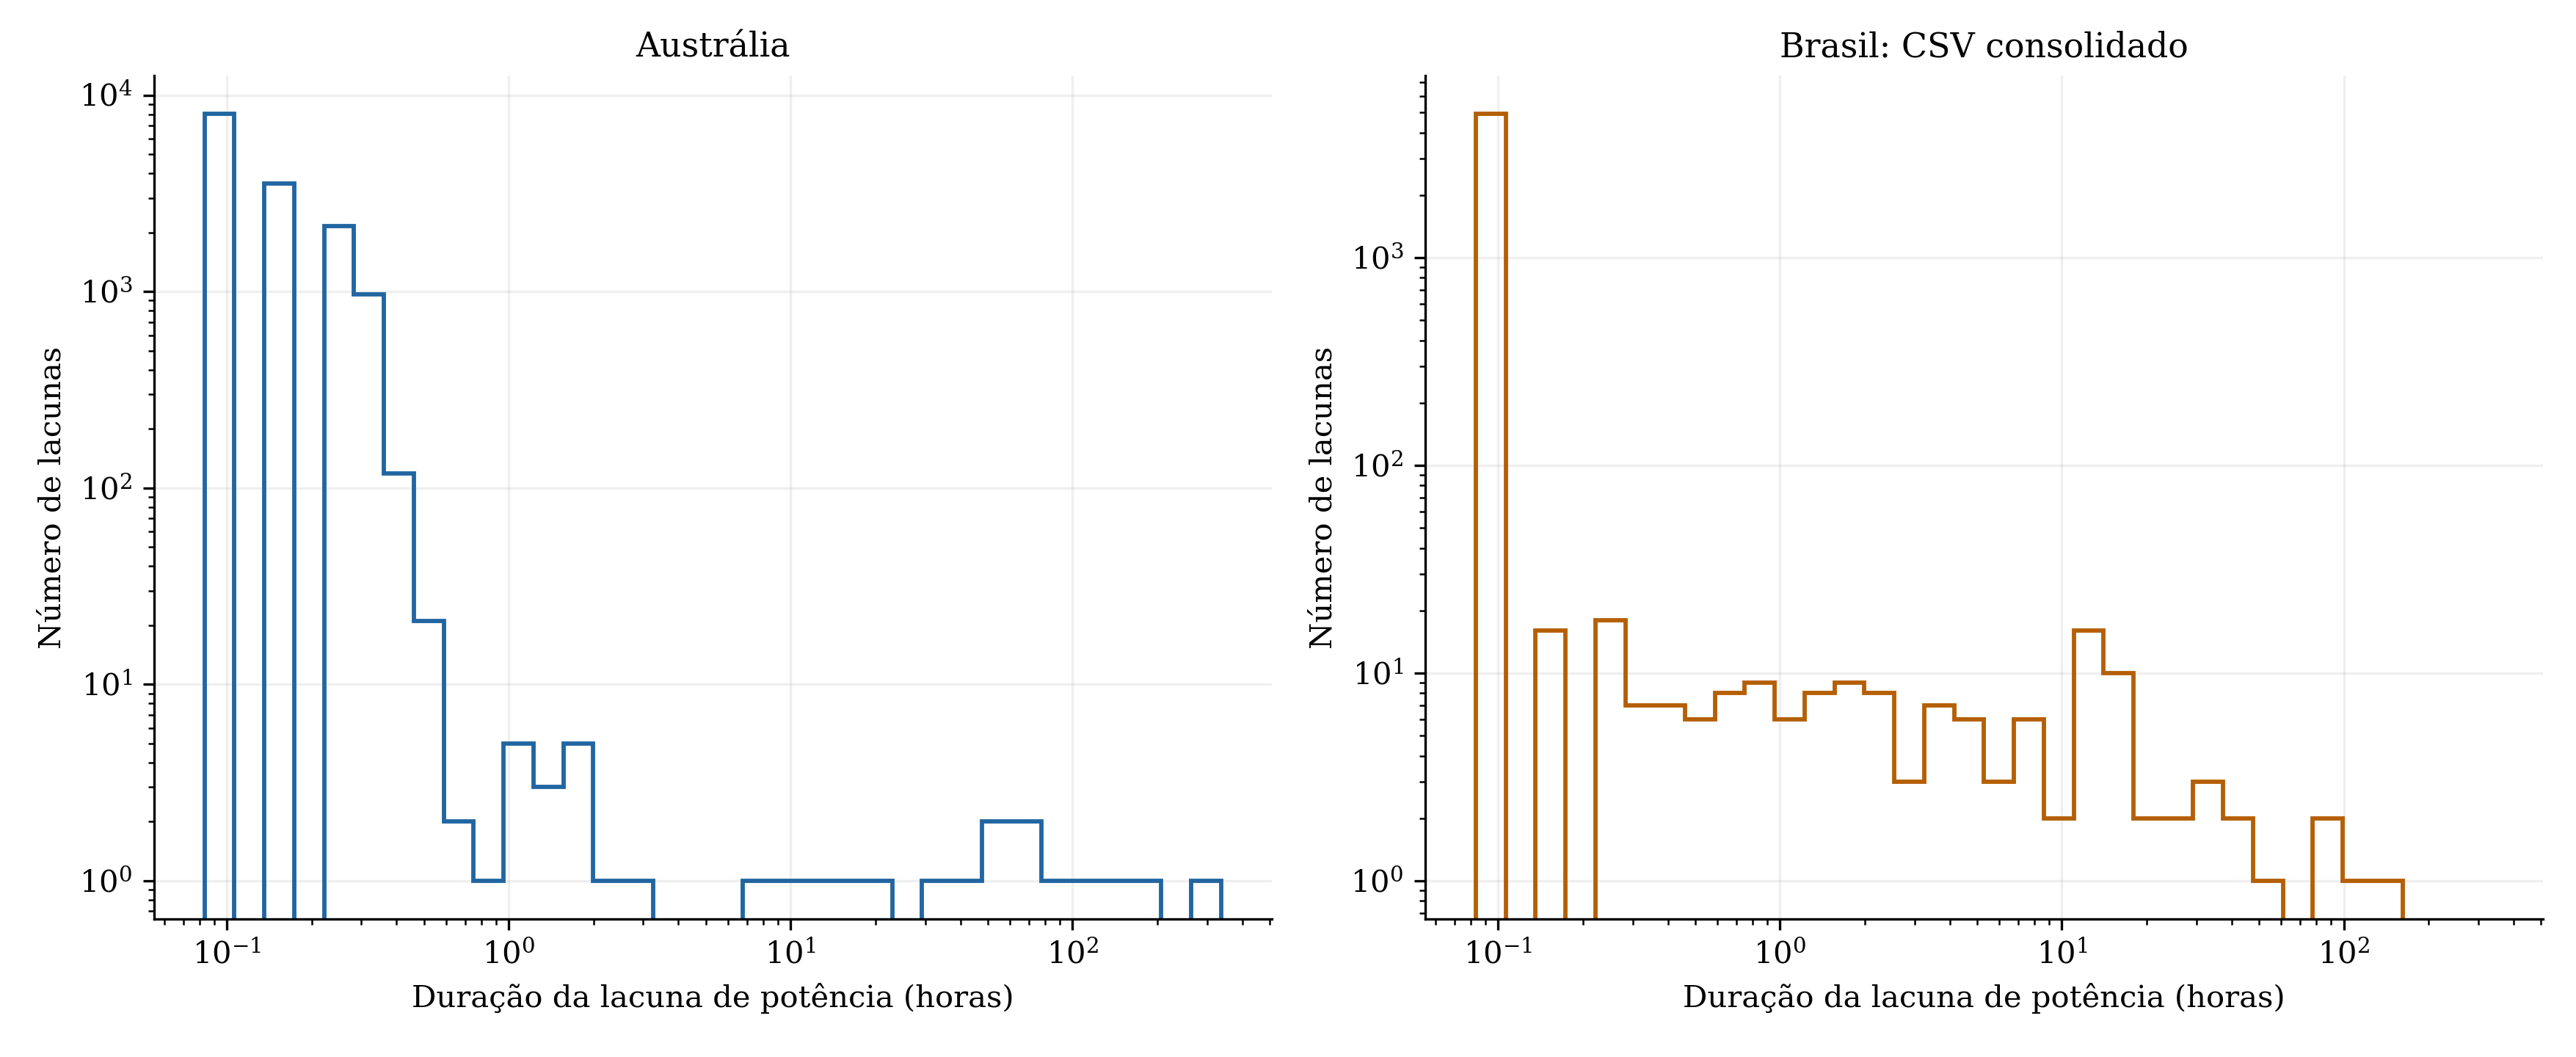

**Figura 3.2-06: Distribuição da duração das lacunas de potência por sistema.** Sequências consecutivas de intervalos de cinco minutos sem potência numérica finita. No Brasil, incluem-se tanto os horários sem linha no CSV consolidado manual quanto as linhas com potência ausente. A duração corresponde ao número de intervalos consecutivos multiplicado por cinco minutos. Incluem-se as bordas do calendário. Os eixos utilizam escala logarítmica.

Fonte: elaboração própria a partir das bases analisadas.

In [9]:
display(tabelas["lacunas_potencia"].sort_values("minutos", ascending=False).head(20))
display(tabelas["flags"].query("intervalos_sinalizados > 0"))
figura(6)


### Auditoria do CSV manual

A tabela identifica o arquivo efetivamente lido, sua quantidade de linhas, período, grade e limites de interpretação. O carregador rejeita horários duplicados ou desalinhados, sem reconsolidar silenciosamente os valores. As regras do gerador `data.ipynb` são apenas documentadas; o notebook do pesquisador não é alterado.


,linhas_csv,linhas_usina_no_ano,ano,usina,inicio_utc,fim_utc,inicio_local,fim_local,intervalos_calendario,horarios_duplicados,horarios_desalinhados,intervalos_com_potencia,regra_presenca,regra_merge_documentada,contribuintes,intervalos_oito_inversores,intervalos_soma_parcial
0,105120,105120,2025,07-07FX,2025-01-01 03:00:00+00:00,2026-01-01 02:55:00+00:00,2025-01-01 00:00:00,2025-12-31 23:55:00,105120,0,0,84235,Indicadores tem_registro_estacao e tem_registr...,data.ipynb usa a grade completa de cinco minut...,n_inversores_potencia distingue somas completa...,82787,1448


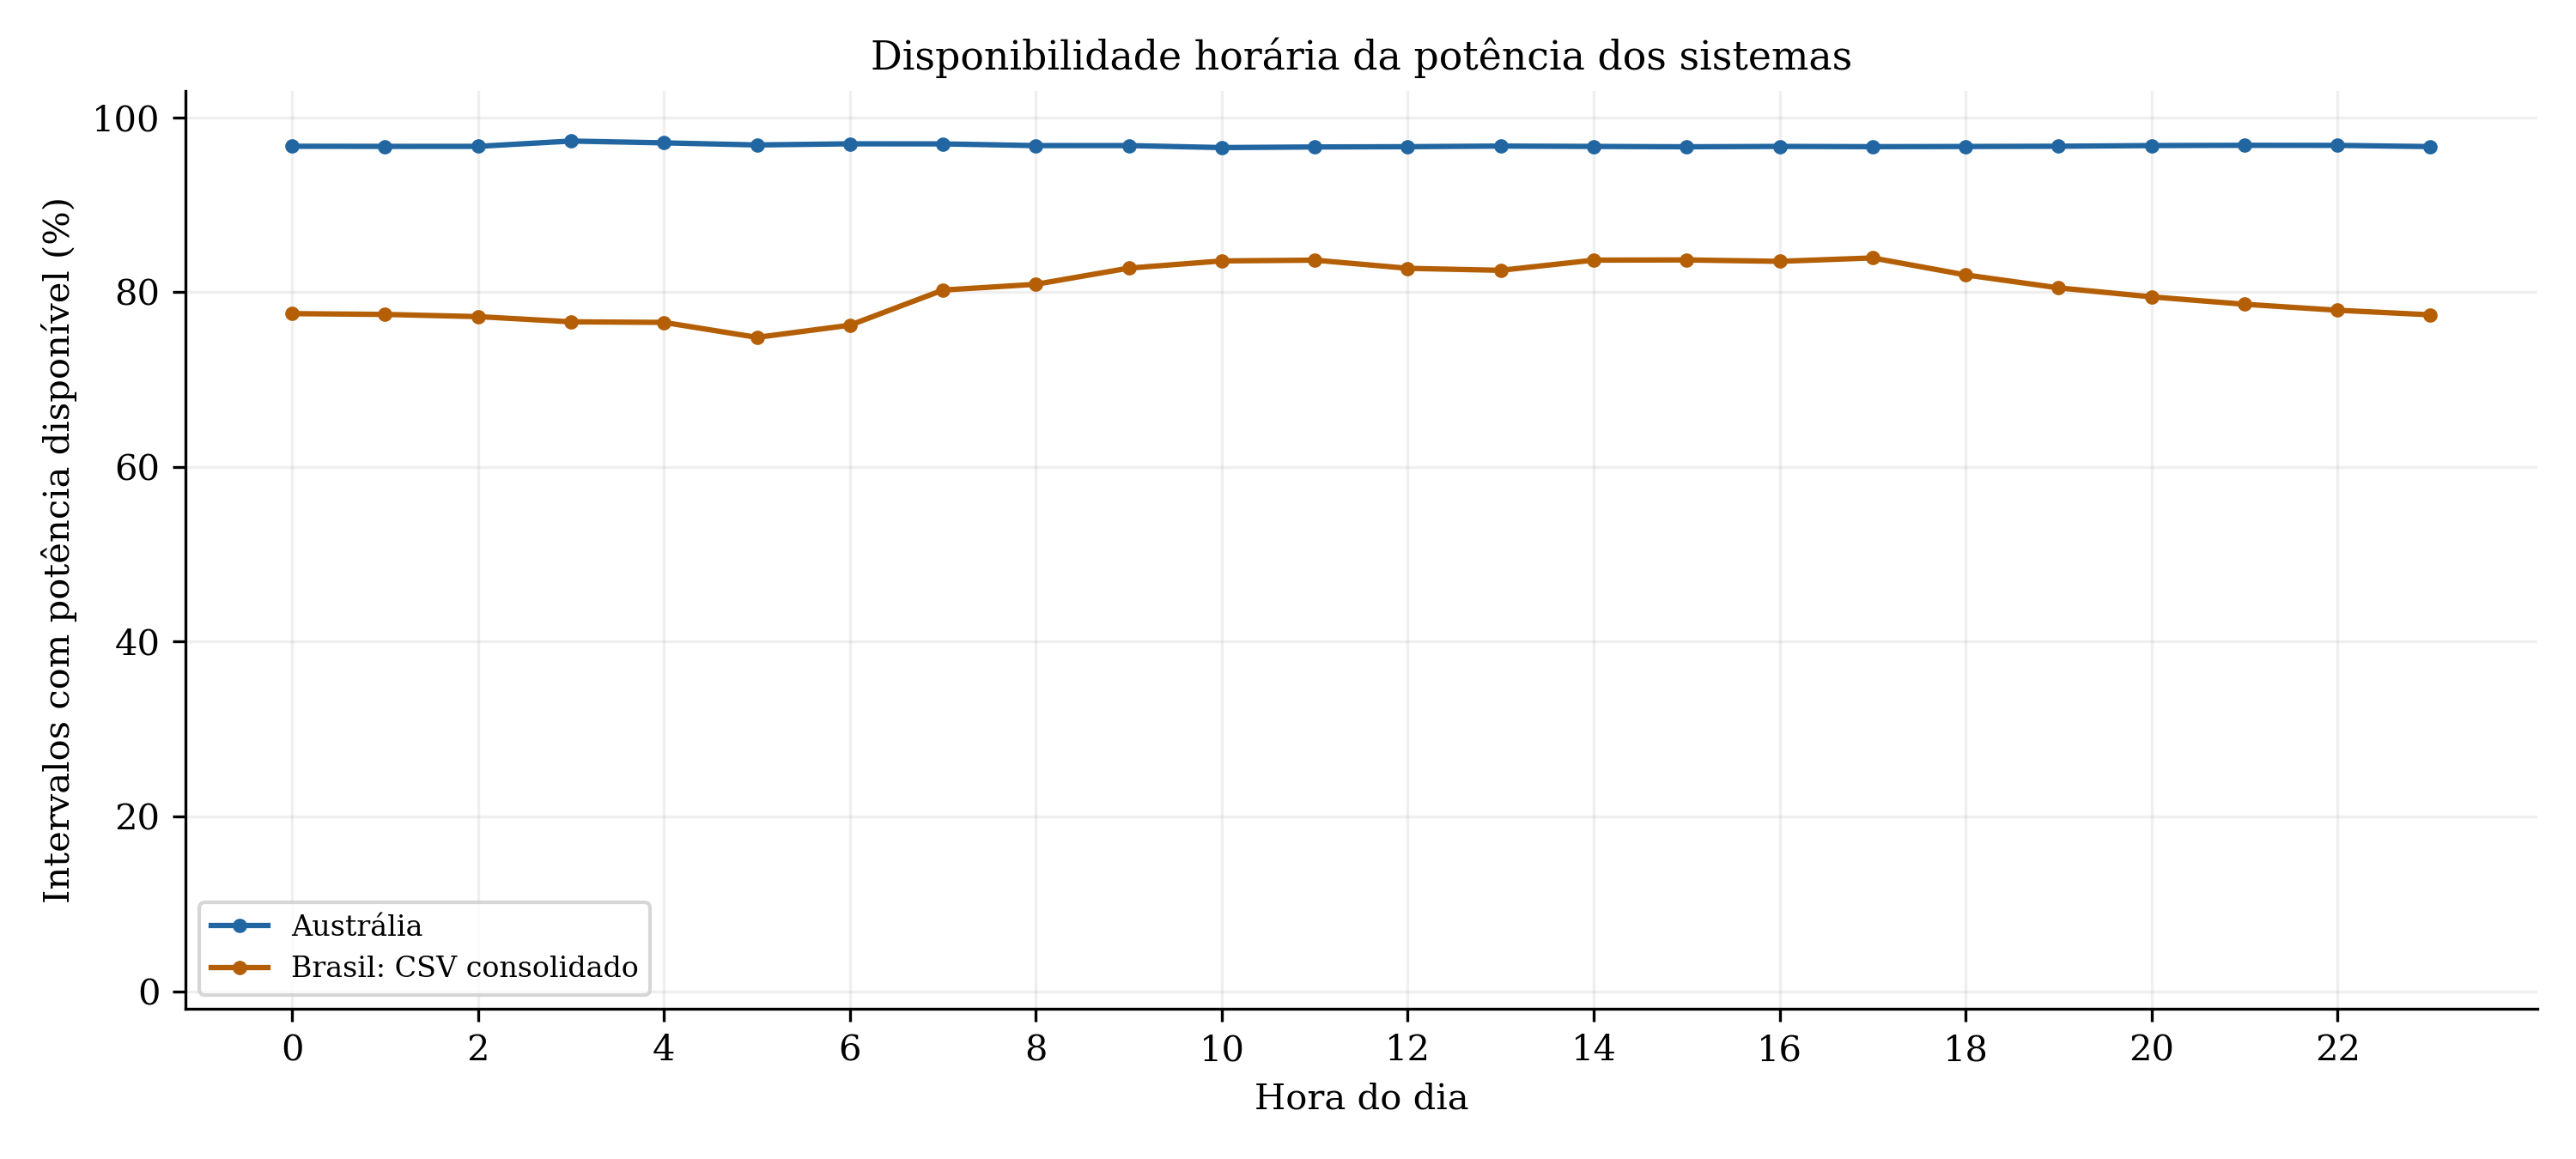

**Figura 3.2-07: Perfil horário da disponibilidade de potência dos sistemas.** Proporção de intervalos com potência numérica finita por hora do dia, incluindo as 24 horas e os zeros observados. A Austrália mantém a convenção temporal do arquivo; o Brasil utiliza America/Sao_Paulo após conversão dos horários UTC. O perfil é descritivo e não atribui causa às ausências.

Fonte: elaboração própria a partir das bases analisadas.

In [10]:
display(tabelas["auditoria_csv_brasil"])
figura(7)


### Inspeção de um período

A tabela brasileira contém a potência do CSV manual, em kW, e os canais da estação. Os valores nos horários existentes são preservados; horários inexistentes aparecem como ausentes na grade de análise. Altere `FONTE`, `INICIO` e `FIM` para consultar outro período.


In [11]:
FONTE = "brasil"  # "australia" ou "brasil"
INICIO, FIM = "2025-02-01", "2025-02-01"
consulta = fontes[FONTE]["valores"].loc[INICIO:FIM]
display(consulta.head(24))
display(consulta.notna().sum().rename("Intervalos com valor disponível").to_frame())


,potencia_total_kw,indice_albedo_medio,gri_kwh_day_est,albedo_tracker,gri_irr_med,poa_kwh_hour,precipitacao_acc,dir_vento,poa_irradiancia,poa_irr_med,air_speed_max,...,air_speed_med,indice_albedo_minimo,gri_kwh_min,gri_kwh_hour,pv_temperatura_min,air_speed_min,precipitacao_acc_day,poa_kwh_acc_est,gri_irr_max,ghi_kwh_acc_est,gri_kwh_acc_est
horario_local,,,,,,,,,,,,,,,,,,,,,,,
2025-02-01 00:00:00,0.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025-02-01 00:05:00,0.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025-02-01 00:10:00,0.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025-02-01 00:15:00,0.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025-02-01 00:20:00,0.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025-02-01 00:25:00,0.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025-02-01 00:30:00,0.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025-02-01 00:35:00,0.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025-02-01 00:40:00,0.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,Intervalos com valor disponível
potencia_total_kw,282
indice_albedo_medio,0
gri_kwh_day_est,0
albedo_tracker,0
gri_irr_med,0
poa_kwh_hour,0
precipitacao_acc,0
dir_vento,0
poa_irradiancia,0
poa_irr_med,0


### Material exportado e limites de interpretação

Os produtos ficam em `reports/tcc/caracterizacao_sistemas/`: sete figuras em PNG/PDF, estatísticas, dicionário com cobertura, lacunas, sinalizadores e tabelas diárias/mensais. `brasil_potencia_estacao_5min.csv` é uma visão de análise do CSV manual na grade completa. `auditoria_csv_brasil.csv` e `manifesto.json` identificam a nova fonte.

O arquivo `Leopoldo_base_consolidada_5min.csv` e `data.ipynb` permanecem inalterados. Não se usa o CSV gerado pelo 03_01 como substituto da fonte escolhida pelo pesquisador. O protocolo diário do 03_03 e seus alvos não são modificados.


In [12]:
display(tabelas["resumo_fontes"])
print("Tabelas:", analise["tabelas_dir"])
print("Figuras:", analise["figuras"])
print("Legendas:", PASTA / "legendas_figuras.md")
print("Fontes e regras:", PASTA / "manifesto.json")


Tabelas: C:\Users\camil\Documents\transfer-learning-energy-forecast-tcc\reports\tcc\caracterizacao_sistemas\tabelas
Figuras: C:\Users\camil\Documents\transfer-learning-energy-forecast-tcc\reports\tcc\caracterizacao_sistemas\figuras
Legendas: C:\Users\camil\Documents\transfer-learning-energy-forecast-tcc\reports\tcc\caracterizacao_sistemas\legendas_figuras.md
Fontes e regras: C:\Users\camil\Documents\transfer-learning-energy-forecast-tcc\reports\tcc\caracterizacao_sistemas\manifesto.json


,fonte,variavel_potencia,inicio,fim,intervalos_esperados,intervalos_com_potencia,cobertura_potencia_pct,variaveis_meteorologicas
0,australia,Active_Power,2013-07-25 00:00:00,2025-08-23 23:55:00,1270944,1229605,96.747,9
1,brasil,potencia_total_kw,2025-01-01 00:00:00,2025-12-31 23:55:00,105120,84235,80.132,55
